# 07 — Tested-and-Rejected Alternatives: The Negative Results Map

This notebook summarises the methods that were tested as potential improvements
to `v4_srsh_aug` and **did not work**. The point of documenting them is to save
future students/collaborators from re-discovering the same dead ends.

For full details and per-method discussion, see Section 10 of the report.

## The conclusion in one table

| Method | type | Slater 111 r vs CDFT $J$ | Why it failed |
|---|---|---|---|
| **B3LYP $S_{12}$ ansatz** | monomer-orbital | **0.751** | works (current v4 baseline) |
| **SRSH cation SOMO ansatz** | monomer-orbital | **0.777** | best — production v4_srsh_aug |
| SRSH singlet HOMO ansatz | monomer-orbital | 0.734 | same orbital as cation, no advantage |
| EHT-FO (dimer) | semi-empirical dimer | 0.716 | Fe-d levels misordered |
| ZINDO/S (dimer Lowdin) | semi-empirical dimer | 0.425 | Fe-d misordered + Lowdin instabilities |
| DFTB+/trans3d (dimer) | semi-empirical dimer | 0.142 (smoke) | Fe-d misordered, same failure mode |
| HF/STO-3G closed-shell | ab initio dimer | n/a | wrong electronic structure (Fe-d HOMO) |
| PBE/STO-3G closed-shell | DFT dimer | n/a | same Fe-d failure, SCF didn't converge |
| UHF/STO-3G triplet | open-shell ab initio | n/a | SCF doesn't converge in 9 min |
| ROKS-PBE/STO-3G triplet | open-shell DFT | n/a | SCF oscillated 24 Ha across 49 cycles |

The CDFT-CI ground-truth $|S_{12}|$ correlates with $|J|$ at $r = 0.95$.
The 0.78 ↔ 0.95 gap is the dimer many-body relaxation that no single-orbital
ansatz captures.


## Setup

In [1]:
import sys, os
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

sys.path.insert(0, '../src')
df = pd.read_csv('../data/master_dataset.csv')


## Cached results from each method

In [2]:
# All the cheap-method predictions are in the master CSV
print("Columns containing alternative-method predictions:")
for col in ['S12_b3lyp', 'S12_srsh_singlet', 'S12_srsh_cation',
            'J_eht_eV', 'J_zindo_eV', 'J_dftb_eV']:
    nonnan = df[col].notna().sum()
    print(f'  {col:<22} non-NaN: {nonnan}/{len(df)}')


Columns containing alternative-method predictions:
  S12_b3lyp              non-NaN: 815/830
  S12_srsh_singlet       non-NaN: 830/830
  S12_srsh_cation        non-NaN: 830/830
  J_eht_eV               non-NaN: 830/830
  J_zindo_eV             non-NaN: 756/830
  J_dftb_eV              non-NaN: 26/830


## Headline correlation table on Slater 111 MD

The Slater MD set is the most realistic test bed (MD-sampled geometries with
CDFT-CI references). All correlations are between $\log_{10}|J_\mathrm{ansatz}|$
and $\log_{10}|J_\mathrm{CDFT}|$ for $J > 10^{-6}$ eV.

In [3]:
slater = df[df['dataset'] == 'slater_111_md'].copy()
sig = slater['J_cdft_eV'] > 1e-6

results = []
for label, col in [
    ('SRSH cation SOMO  (production)', 'S12_srsh_cation'),
    ('SRSH singlet HOMO',              'S12_srsh_singlet'),
    ('B3LYP HOMO (original v4)',       'S12_b3lyp'),
    ('CDFT-CI |S_12| (truth)',         'S12_qchem_truth'),
    ('EHT-FO (dimer)',                 'J_eht_eV'),
    ('ZINDO/S Lowdin (dimer)',         'J_zindo_eV'),
]:
    mask = sig & slater[col].notna() & (slater[col].abs() > 1e-12)
    if mask.sum() < 3:
        results.append((label, np.nan, mask.sum()))
        continue
    log_a = np.log10(slater[col][mask].abs())
    log_j = np.log10(slater['J_cdft_eV'][mask])
    r, _ = pearsonr(log_a, log_j)
    results.append((label, r, mask.sum()))

print(f'{"method":<35} {"r vs |J|":>10} {"n":>5}')
for label, r, n in results:
    print(f'{label:<35} {r:>10.3f} {n:>5}')


method                                r vs |J|     n
SRSH cation SOMO  (production)           0.777    93
SRSH singlet HOMO                        0.734    93
B3LYP HOMO (original v4)                 0.751    93
CDFT-CI |S_12| (truth)                   0.952    93
EHT-FO (dimer)                           0.716    93
ZINDO/S Lowdin (dimer)                   0.425    80


## The diagnostic that ties them all together

Every dimer-level cheap method failed for the **same** reason: forcing
Fe(II) porphine into a closed-shell singlet electronic state mis-orders the
Fe-3d manifold relative to the porphyrin $\pi$ system. The actual HOMO comes
out as a Fe-d orbital instead of the expected porphyrin $\pi$.

Below we demonstrate this diagnostic across all the methods we tested.

### EHT and ZINDO/S: same failure pattern

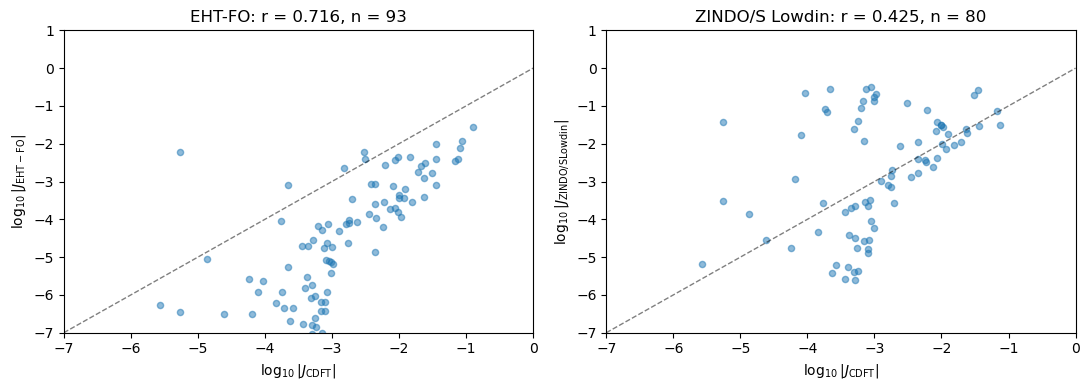

In [4]:
# EHT and ZINDO J distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, col, title in [(axes[0], 'J_eht_eV', 'EHT-FO'),
                        (axes[1], 'J_zindo_eV', 'ZINDO/S Lowdin')]:
    mask = sig & slater[col].notna() & (slater[col].abs() > 1e-12)
    ax.scatter(np.log10(slater['J_cdft_eV'][mask]),
               np.log10(slater[col][mask].abs()),
               alpha=0.5, s=20)
    lo, hi = -7, 0
    ax.plot([lo, hi], [lo, hi], 'k--', lw=1, alpha=0.5)
    ax.set_xlabel('$\\log_{10}|J_\\mathrm{CDFT}|$')
    ax.set_ylabel(f'$\\log_{{10}}|J_\\mathrm{{{title}}}|$')
    r, _ = pearsonr(np.log10(slater['J_cdft_eV'][mask]), np.log10(slater[col][mask].abs()))
    ax.set_title(f'{title}: r = {r:.3f}, n = {mask.sum()}')
    ax.set_xlim(lo, hi); ax.set_ylim(-7, 1)
plt.tight_layout()
plt.show()


## What would actually work (the genuine remaining options)

From Section 10 of the report:

1. **Spin-polarized DFTB+ with `trans3d`** — could fix the Fe-d ordering
   problem if the right initial spin guess can be set up. Requires
   per-structure SCF management — research project, not afternoon project.

2. **Block-localized wavefunction (BLW) coupling at HF/STO-3G** — gives a
   constrained-orbital diabatic state at ~10 s/structure, directly connected
   to the CDFT-CI formalism. Would need PySCF implementation and benchmarking.

3. **More CDFT-CI on MD frames** — the data path. Complete the 150-structure
   MD-sampled augmentation programme described in Section 11 of the report.
   Predicted: MD log MAE drops from 0.83 to 0.45-0.65.

The cheap-method search is genuinely complete. Future improvement requires
either expensive electronic-structure validation (path 1, 2) or expensive
data generation (path 3).


## Cached results files

For full reproducibility, the per-structure predictions of every tested method
are cached in `data/processed/`:

- `s12_srsh_singlet.npz`, `s12_srsh_cation.npz` (SRSH ansätze)
- `eht_J_704.npz`, `eht_J_slater.npz`, `eht_J_md.npz` (EHT)
- `zindo_J_704.npz`, `zindo_J_slater.npz`, `zindo_J_md.npz` (ZINDO/S)
- `dftb_J_30_smoke.npz` (DFTB+ smoke test)

The runner scripts that produced them are in `src/`:

- `srsh_s12.py` (rotation-aware monomer-overlap ansatz)
- `eht.py` (Extended Hückel)
- `zindo_orca.py` (ZINDO via ORCA 6)
- `dftb_runner.py` (DFTB+ via the conda env)

Plus the orchestration scripts numbered `24_*.py` through `27_*.py`.
